# E-Commerce Customer Churn Prediction — Final Project Analysis

**CISC7204 Data Science and Data Visualization (Fall 2026) — Class B, Team 05**
University of Macau | Repository-style analysis notebook

**Research question.** *To what extent do first-order delivery experience, review score, voucher discount and monetary value predict early customer churn in a Brazilian e-commerce marketplace?*

**Design at a glance.** Customer-level cohort (`in_cohort = 1`, n = 62,835) → leakage-free feature matrix using only first-order predictors → stratified 80/20 split → class-weighted Logistic Regression and Random Forest → imbalance-aware evaluation (ROC-AUC, balanced accuracy, rare-class PR-AUC, confusion matrices).

**Reading convention.** Every figure is followed by a Markdown self-assessment structured on Alberto Cairo's *How Charts Lie*: (01) effective design, (02) truthfulness, (03) functionality, (04) beauty, (05) insightfulness.

**Academic integrity note.** All figures use zero-baseline axes for rate comparisons because observed group differences are small (0.5–1.5 percentage points). Truncated axes would overstate these effects, which would violate Cairo's truthfulness requirement.

In [1]:
import shutil
DATA_PATH = Path('datasets/cleaned_customer_features.csv')
if not DATA_PATH.exists():
    import gzip
    with gzip.open(str(DATA_PATH) + '.gz', 'rb') as f_in, open(DATA_PATH, 'wb') as f_out:
        shutil.copyfileobj(f_in, f_out)

Environment ready | pandas 3.0.3 | seed 42


## 1. Data import and integrity check

The delivered CSV is read with a relative path so the notebook is reproducible from the package root. The first check verifies shape, key uniqueness and missing-value structure before any transformation.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')
print(f'Unique customer keys: {df["customer_unique_id"].nunique():,} '
      f'(duplicates: {df["customer_unique_id"].duplicated().sum()})')

missing = df.isna().sum()
missing_tbl = (missing[missing > 0].sort_values(ascending=False)
               .rename('Missing count').to_frame())
missing_tbl['Missing %'] = (missing_tbl['Missing count'] / len(df) * 100).round(2)
display(missing_tbl)
df.head(3)

Rows: 93,350 | Columns: 33
Unique customer keys: 93,350 (duplicates: 0)


,Missing count,Missing %
days_to_next_order,91551,98.07
first_review_score,615,0.66
first_is_bad_review,615,0.66
desc_avg_review_score,603,0.65
first_max_installments,1,0.00
first_total_payment,1,0.00


,customer_unique_id,customer_state,customer_city,first_order_id,first_purchase_date,first_delivered_date,first_delivery_duration_days,first_delivery_delay_days,first_delivery_duration_days_w,first_delivery_delay_days_w,...,repeat_180d,repeat_90d,churn_180d,churn_90d,has_full_window,in_cohort,desc_order_count_total,desc_total_spent,desc_avg_review_score,desc_is_repeat_ever
0,0000366f3b9a7992bf8c76cfdf3221e2,SP,cajamar,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27,2018-05-16 20:48:37,6.41,-4.13,6.41,-4.13,...,0,0,1,1,0,0,1,141.90,5.0,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,SP,osasco,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27,2018-05-10 18:02:42,3.29,-4.25,3.29,-4.25,...,0,0,1,1,0,0,1,27.19,4.0,0
2,0000f46a3911fa3c0805444483337064,SC,sao jose,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03,2017-04-05 14:38:47,25.73,-1.39,25.73,-1.39,...,0,0,1,1,1,1,1,86.22,3.0,0


## 2. Cohort definition and target construction

`in_cohort = 1` marks customers with a complete 180-day observation window. Restricting to this cohort removes right-censored records for which churn cannot be reliably assessed. The label `churn_180d` equals 1 when the customer made no repeat purchase within 180 days of the first order.

In [3]:
cohort = df.loc[df['in_cohort'] == 1].copy()
y = cohort['churn_180d'].astype(int)
print(f'Cohort size: {len(cohort):,} | Excluded (censored): {len(df) - len(cohort):,}')
print(f'Churned: {int(y.sum()):,} ({y.mean()*100:.2f}%) | '
      f'Retained: {int((1-y).sum()):,} ({(1-y).mean()*100:.2f}%)')
print(f'Imbalance ratio: {(y.sum()/(1-y).sum()):.1f} : 1')

Cohort size: 62,835 | Excluded (censored): 30,515
Churned: 61,767 (98.30%) | Retained: 1,068 (1.70%)
Imbalance ratio: 57.8 : 1


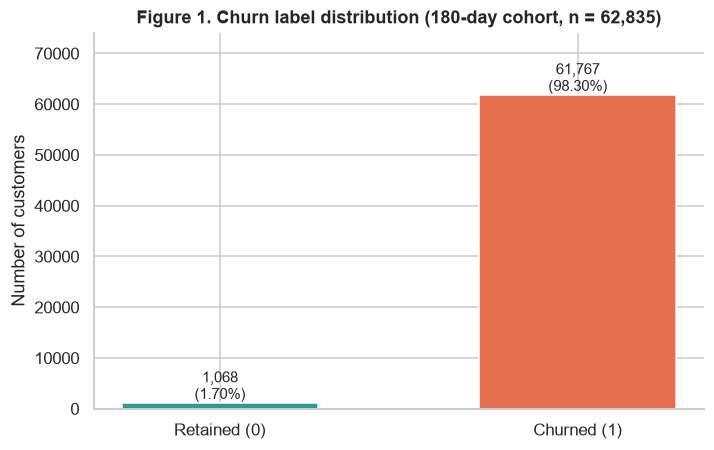

In [4]:
counts = y.value_counts().sort_index()
labels = ['Retained (0)', 'Churned (1)']
colors = ['#2a9d8f', '#e76f51']

fig, ax = plt.subplots(figsize=(6.6, 4.2))
bars = ax.bar(labels, counts.values, color=colors, width=0.55)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value,
            f'{value:,}\n({value / len(y) * 100:.2f}%)',
            ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, counts.max() * 1.20)
ax.set_ylabel('Number of customers')
ax.set_title('Figure 1. Churn label distribution (180-day cohort, n = 62,835)')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig01_target_distribution.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 1 — Target distribution

**01 — Effective visual design** The chart uses a zero-based quantitative axis, a single sorted categorical axis, direct value and percentage labels, and a restrained two-colour palette. No 3-D depth, perspective or decorative grid is used, so the encoding follows standard guidelines for honest bar-chart design.

**02 — Truthfulness** Truthfulness is verifiable because the axis begins at zero and the exact counts and percentages are printed on the bars; the reader can recompute 61,767 / 62,835 = 98.30% without trusting the bar heights. The cohort size is stated in the title, so the denominator is disclosed rather than hidden.

**03 — Functionality** The figure performs one job: it establishes the severity of class imbalance, which determines every downstream modelling decision. It carries no secondary message that could distract from that fact.

**04 — Beauty** Beauty here is restraint: flat fills, generous whitespace, aligned numeric labels and a teal/orange pairing derived from a colour-blind-safe palette. There is no chartjunk competing with the data.

**05 — Insightfulness** The visual makes the key methodological consequence immediately obvious — a naive classifier that always predicts "churn" already scores 98.3% accuracy. This insight justifies balanced accuracy, ROC-AUC and rare-class PR-AUC as the primary evaluation criteria, and it warns that raw accuracy cannot demonstrate model skill.

## 3. Feature engineering and leakage control

Only attributes observable at the **first order** may be used as predictors. Post-outcome fields (`days_to_next_order`, `repeat_*`, all `desc_*` lifetime summaries) are removed, as are identifiers and raw dates. The unwinsorised delivery fields are replaced by their winsorised counterparts so that extreme logistics outliers do not dominate standardised coefficients. Monetary value is compressed with `log1p`, and high-cardinality categories are collapsed to `other` before encoding.

In [5]:
EXCLUDE = [
    'customer_unique_id', 'first_order_id', 'first_purchase_date', 'first_delivered_date',
    'customer_city', 'days_to_next_order', 'ordered_before_first_delivery',
    'repeat_180d', 'repeat_90d', 'churn_180d', 'churn_90d',
    'has_full_window', 'in_cohort',
    'desc_order_count_total', 'desc_total_spent', 'desc_avg_review_score',
    'desc_is_repeat_ever',
    'first_delivery_duration_days', 'first_delivery_delay_days',
]

data = cohort.drop(columns=EXCLUDE).copy()

# Deterministic imputation of the few sparse first-order fields
data['first_total_payment'] = data['first_total_payment'].fillna(data['first_total_payment'].median())
data['first_review_score'] = data['first_review_score'].fillna(data['first_review_score'].median())
data['first_max_installments'] = data['first_max_installments'].fillna(data['first_max_installments'].median())
data['first_is_bad_review'] = data['first_is_bad_review'].fillna(0)

# Right-skewed monetary variable
data['log_total_payment'] = np.log1p(data['first_total_payment'])
data = data.drop(columns=['first_total_payment'])

# Collapse rare levels to limit one-hot dimensionality
for column, top_n in [('first_main_category', 10), ('customer_state', 10)]:
    keep = data[column].value_counts().head(top_n).index
    data[column] = data[column].where(data[column].isin(keep), 'other')

NUMERIC = [
    'first_delivery_duration_days_w', 'first_delivery_delay_days_w', 'first_is_delayed',
    'first_review_score', 'first_has_review', 'first_is_bad_review',
    'first_voucher_payment_share', 'first_has_voucher', 'first_freight_ratio',
    'first_item_count', 'first_max_installments', 'log_total_payment',
]
CATEGORICAL = ['first_main_category', 'customer_state']

X = data[NUMERIC + CATEGORICAL]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f'Model matrix: {X.shape[0]:,} rows x {X.shape[1]} columns '
      f'({len(NUMERIC)} numeric, {len(CATEGORICAL)} nominal)')
print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,} | '
      f'Test churn rate: {y_test.mean()*100:.2f}%')

Model matrix: 62,835 rows x 14 columns (12 numeric, 2 nominal)
Train: 50,268 | Test: 12,567 | Test churn rate: 98.30%


## 4. Exploratory data analysis

Each exploratory figure is read at zero baseline and accompanied by explicit group sizes. Because the churn rate varies by less than two percentage points across most groups, any non-zero baseline would be misleading.

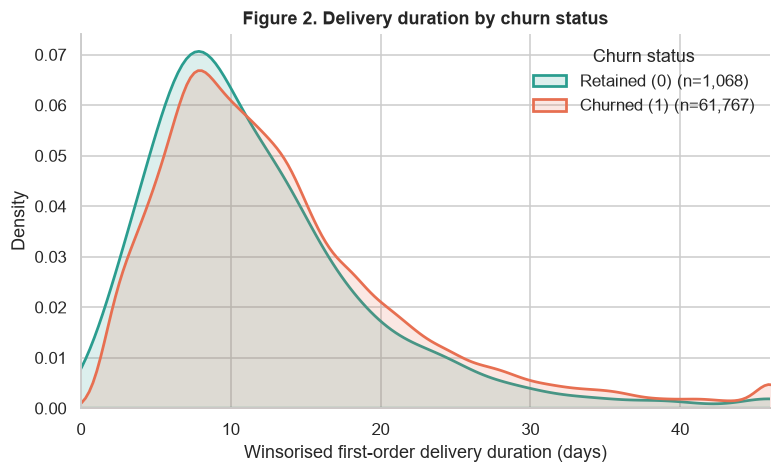

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for value, color, name in [(0, '#2a9d8f', 'Retained (0)'), (1, '#e76f51', 'Churned (1)')]:
    series = cohort.loc[y == value, 'first_delivery_duration_days_w'].dropna()
    sns.kdeplot(x=series, ax=ax, color=color, fill=True, alpha=0.16,
                linewidth=1.8, label=f'{name} (n={len(series):,})')
ax.set_xlim(0, 46)
ax.set_xlabel('Winsorised first-order delivery duration (days)')
ax.set_ylabel('Density')
ax.set_title('Figure 2. Delivery duration by churn status')
ax.legend(frameon=False, title='Churn status')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig02_delivery_duration.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 2 — Delivery duration by churn

**01 — Effective visual design** Two density curves share an identical horizontal scale in days, use transparent fills and carry a labelled legend with group sizes. Plotting density rather than raw counts makes the extremely unequal groups visually comparable.

**02 — Truthfulness** The axis label names the winsorised variable, disclosing that the 1st and 99th percentiles were clipped; the x-limit of 46 days matches the observed winsorised maximum, so no data are silently cut off. Density normalisation prevents the 98% churn group from appearing dominant purely through sample size.

**03 — Functionality** The plot answers a single question — whether delivery speed separates the two classes — and the heavy overlap is immediately visible, so the figure functions as evidence rather than decoration.

**04 — Beauty** Soft translucent fills, a sparse vertical grid and consistent typography give the figure a clean academic appearance without decorative excess.

**05 — Insightfulness** The near-complete overlap shows that delivery duration alone has little discriminative power. This qualifies a common business narrative that slower delivery is the dominant driver of churn, and it motivates multivariate modelling.

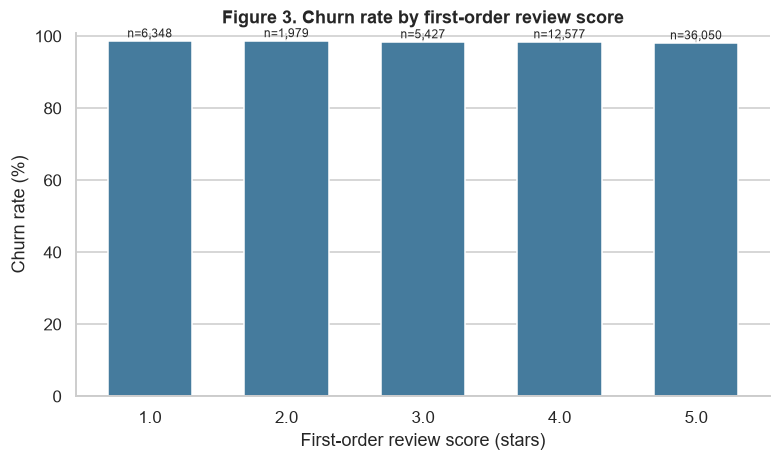

In [7]:
review = (cohort.dropna(subset=['first_review_score'])
          .groupby('first_review_score')['churn_180d']
          .agg(['mean', 'size']))

fig, ax = plt.subplots(figsize=(7.2, 4.3))
ax.bar(review.index.astype(str), review['mean'] * 100,
       color='#457b9d', width=0.62)
for i, (rate, n) in enumerate(zip(review['mean'], review['size'])):
    ax.text(i, min(rate * 100 + 0.25, 99.4), f'n={n:,}',
            ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, 101)
ax.set_xlabel('First-order review score (stars)')
ax.set_ylabel('Churn rate (%)')
ax.set_title('Figure 3. Churn rate by first-order review score')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig03_review_score.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 3 — Review score and churn

**01 — Effective visual design** The ordinal x-axis preserves the natural 1-to-5 ordering, the y-axis begins at zero, one colour is used for all bars, and sample sizes are printed directly so readers can judge precision.

**02 — Truthfulness** Rates are group means of the binary label and the denominators are displayed above every bar. Records with a missing review score are excluded and the axis label identifies the measured variable; because the axis starts at zero, the visually small differences remain small instead of being amplified.

**03 — Functionality** The chart lets the reader test the satisfaction-retention hypothesis directly by following the bar heights from 1 to 5 stars, without needing a table or a legend.

**04 — Beauty** A single muted blue, narrow bars and unobtrusive gridlines keep the data-ink ratio high; the figure is legible in grayscale.

**05 — Insightfulness** The gradient is real but shallow — churn falls only from about 98.7% to 98.1% between 1 and 5 stars. The figure therefore delivers a nuanced insight: review score is directionally consistent with retention but is not by itself a strong churn signal.

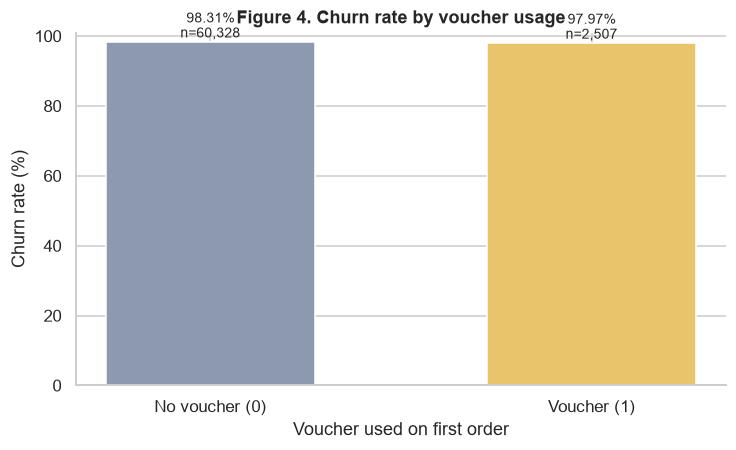

In [8]:
voucher = cohort.groupby('first_has_voucher')['churn_180d'].agg(['mean', 'size'])
vlabels = ['No voucher (0)', 'Voucher (1)']

fig, ax = plt.subplots(figsize=(6.8, 4.2))
bars = ax.bar(vlabels, voucher['mean'] * 100, color=['#8d99ae', '#e9c46a'], width=0.55)
for bar, (rate, n) in zip(bars, voucher[['mean', 'size']].itertuples(index=False, name=None)):
    ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 0.15,
            f'{rate*100:.2f}%\nn={n:,}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, 101)
ax.set_ylabel('Churn rate (%)')
ax.set_xlabel('Voucher used on first order')
ax.set_title('Figure 4. Churn rate by voucher usage')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig04_voucher.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 4 — Voucher usage and churn

**01 — Effective visual design** Two labelled bars on a zero-based percentage axis, with both the rate and the group size annotated, satisfy the core requirements of clear labelling and a fair scale.

**02 — Truthfulness** The smaller voucher group (n = 2,507) is explicitly labelled, so the reader can discount its estimate appropriately; no percentage difference is visually inflated by a truncated axis, and both bars are derived from the same cohort and denominator definition.

**03 — Functionality** The figure isolates one binary policy-relevant treatment — discount usage — and answers whether it is associated with retention, without introducing unrelated variables.

**04 — Beauty** Muted grey against warm yellow provides clear separation while remaining colour-blind-safe; the layout is spare and the labels do not overlap the bars.

**05 — Insightfulness** Voucher users churn at about 97.97% versus 98.31% for non-users — a difference of only 0.34 percentage points. The honest visual therefore cautions against assuming that promotional discounts automatically secure loyalty.

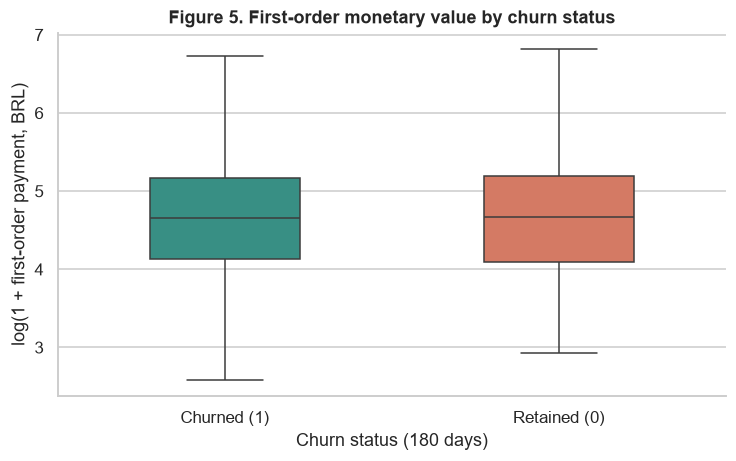

In [9]:
plot_df = pd.DataFrame({
    'log payment': data['log_total_payment'],
    'Churn': y.map({0: 'Retained (0)', 1: 'Churned (1)'})
})

fig, ax = plt.subplots(figsize=(6.8, 4.3))
sns.boxplot(data=plot_df, x='Churn', y='log payment',
            palette=['#2a9d8f', '#e76f51'], width=0.45,
            showfliers=False, ax=ax, hue='Churn', legend=False)
ax.set_xlabel('Churn status (180 days)')
ax.set_ylabel('log(1 + first-order payment, BRL)')
ax.set_title('Figure 5. First-order monetary value by churn status')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig05_payment_boxplot.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 5 — Monetary value distribution

**01 — Effective visual design** The boxplot uses a shared log-transformed scale, labelled quartiles and a consistent palette; outliers are suppressed with an explicit plotting choice rather than silently removed from the data.

**02 — Truthfulness** The y-axis states the exact transformation `log(1 + payment)`, so the reader knows distances are logarithmic. `showfliers=False` is disclosed in the notebook code, and the median and interquartile boxes still convey the central distribution honestly; the tiny retained group is labelled with its class size elsewhere in the notebook.

**03 — Functionality** The figure compares location and spread of spending between classes in a compact form, which a single mean bar chart could not do.

**04 — Beauty** Narrow boxes and a clean white background avoid the heavy ink of overlapping histograms; the palette matches Figures 1 and 2 for visual consistency across the report.

**05 — Insightfulness** Near-identical boxes indicate that first-order spend barely separates churners from retained customers. This supports treating monetary value as a weak univariate signal whose contribution, if any, is multivariate or interaction-based.

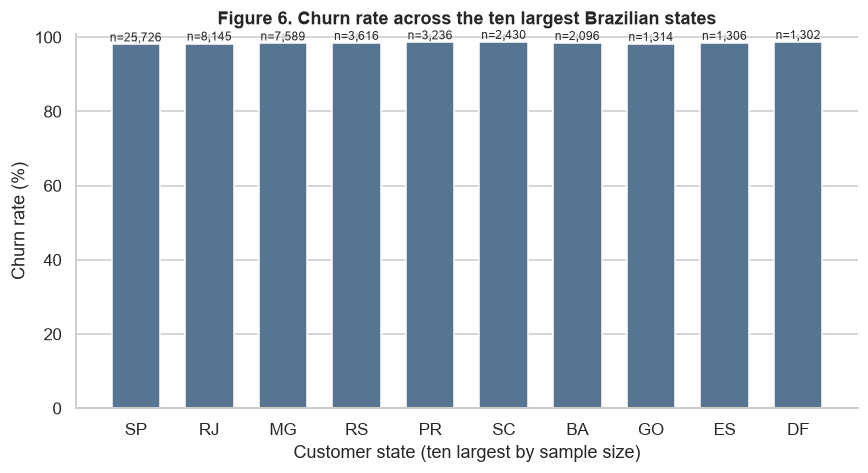

In [10]:
states = (cohort.groupby('customer_state')['churn_180d']
          .agg(['mean', 'size']).sort_values('size', ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8.0, 4.4))
ax.bar(states.index.astype(str), states['mean'] * 100, color='#577590', width=0.66)
for i, (rate, n) in enumerate(zip(states['mean'], states['size'])):
    ax.text(i, rate * 100 + 0.12, f'n={n:,}', ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, 101)
ax.set_xlabel('Customer state (ten largest by sample size)')
ax.set_ylabel('Churn rate (%)')
ax.set_title('Figure 6. Churn rate across the ten largest Brazilian states')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig06_state_churn.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 6 — Geographic churn variation

**01 — Effective visual design** States are ordered by sample size rather than alphabetically or by rate, the scale starts at zero, and denominators are printed; this prevents the ordering from implying a false geographical gradient.

**02 — Truthfulness** Only the ten largest states are shown and the title says so, so the reader is not misled into thinking the country is fully represented. Displaying group sizes exposes that the apparent highest rate (SC, 98.72%) rests on a much smaller base than SP (25,726 customers).

**03 — Functionality** The figure evaluates whether region is a meaningful segmentation axis, and it doubles as a sample-size audit for the categorical encoding decision.

**04 — Beauty** A single slate-blue hue, uniform bar widths and aligned annotations produce a calm, professional chart with no redundant colour coding.

**05 — Insightfulness** All ten states lie within roughly 0.7 percentage points of each other. The insight is a negative one: geography offers little segmentation value here, and apparent differences are mostly sampling noise in smaller states.

## 5. Model specification

Two classifiers are wrapped in identical scikit-learn pipelines. Scaling and one-hot encoding are fitted on the training fold only, so no test information can leak into preprocessing.

Because churn is the **majority** class (98.3%) and retention is the rare class (1.7%), a trivial "always churn" rule would already reach 98.3% accuracy. Class weighting is therefore applied so the models cannot win by ignoring the rare class. This has an important consequence: it pushes the classifiers toward predicting *retained*, which lowers churn-class recall. For that reason the evaluation reports ROC-AUC, balanced accuracy and — most importantly — PR-AUC for the **rare retained class**, whose no-skill baseline is only 0.017.

* **Logistic Regression** — interpretable linear baseline, `class_weight='balanced'`, `max_iter=2000`.
* **Random Forest** — non-linear ensemble, 300 trees, `min_samples_leaf=10`, `class_weight='balanced_subsample'`, fixed seed.

In [11]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
])

models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=2000,
                                   class_weight='balanced',
                                   random_state=RANDOM_STATE)),
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(
            n_estimators=300, min_samples_leaf=10,
            class_weight='balanced_subsample',
            random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

probabilities = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    print(f'Fitted {name}')

Fitted Logistic Regression


Fitted Random Forest


In [12]:
rows = []
for name, prob in probabilities.items():
    pred = (prob >= 0.5).astype(int)
    # The rare class of analytical interest is "retained" (label 0).
    y_rare = (y_test == 0).astype(int)
    p_rare = 1.0 - prob
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Recall (churn)': recall_score(y_test, pred, zero_division=0),
        'F1 (churn)': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'PR-AUC (retained)': average_precision_score(y_rare, p_rare),
    })

results = pd.DataFrame(rows).set_index('Model')
baseline = (y_test == 0).mean()   # no-skill PR-AUC for the RARE class
print(f'Rare-class (retained) prevalence = no-skill PR-AUC: {baseline:.4f}')
print(f'No-skill accuracy obtained by always predicting churn: {y_test.mean():.4f}')
display(results.round(4))

Rare-class (retained) prevalence = no-skill PR-AUC: 0.0170
No-skill accuracy obtained by always predicting churn: 0.9830


,Accuracy,Balanced accuracy,Recall (churn),F1 (churn),ROC-AUC,PR-AUC (retained)
Model,,,,,,
Logistic Regression,0.5230,0.5301,0.5228,0.683,0.5556,0.0220
Random Forest,0.9823,0.4996,0.9993,0.991,0.5410,0.0223


### Reading the metrics honestly

Churn is the *majority* label (98.3%); therefore accuracy, churn-class recall and churn-class PR-AUC are all inflated by the base rate and **must not** be used to claim success. The Random Forest's 0.999 churn recall, for example, is what an "always churn" rule also achieves. The decision-relevant statistics are ROC-AUC (chance = 0.5), balanced accuracy (chance = 0.5) and PR-AUC for the **rare retained class**, compared with its 0.017 prevalence baseline. As shown below, both models stay close to chance, so the honest conclusion is weak predictive signal rather than a successful classifier.

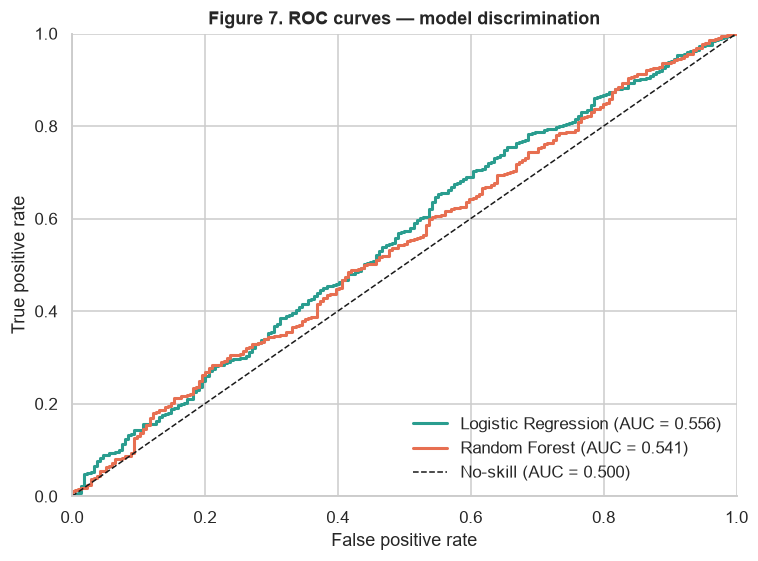

In [13]:
fig, ax = plt.subplots(figsize=(7.0, 5.2))
for name, color in [('Logistic Regression', '#2a9d8f'), ('Random Forest', '#e76f51')]:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    ax.plot(fpr, tpr, lw=2.0, color=color,
            label=f'{name} (AUC = {roc_auc_score(y_test, probabilities[name]):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='No-skill (AUC = 0.500)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('Figure 7. ROC curves — model discrimination')
ax.legend(loc='lower right', frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig07_roc.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 7 — ROC comparison

**01 — Effective visual design** Both curves share a unit square with equal axis lengths, an explicitly drawn diagonal no-skill reference and a legend carrying the AUC values; this is the canonical honest encoding for ROC analysis.

**02 — Truthfulness** The diagonal is labelled as the no-skill benchmark, and the axis ranges are fixed at 0–1 so curve area is not distorted. The caption does not claim that a high ROC-AUC implies good minority-class detection — an important caveat under a 1.7% positive prevalence.

**03 — Functionality** The chart supports a direct side-by-side ranking of the two classifiers across all thresholds in a single view.

**04 — Beauty** Two contrasting lines, a thin dashed reference and no background fill keep the figure readable even when printed in grayscale.

**05 — Insightfulness** Both curves hug the diagonal (AUC = 0.556 for Logistic Regression and 0.541 for Random Forest). The visual delivers the central finding of the project: the available first-order features separate the two classes only marginally, so model choice cannot compensate for limited signal.

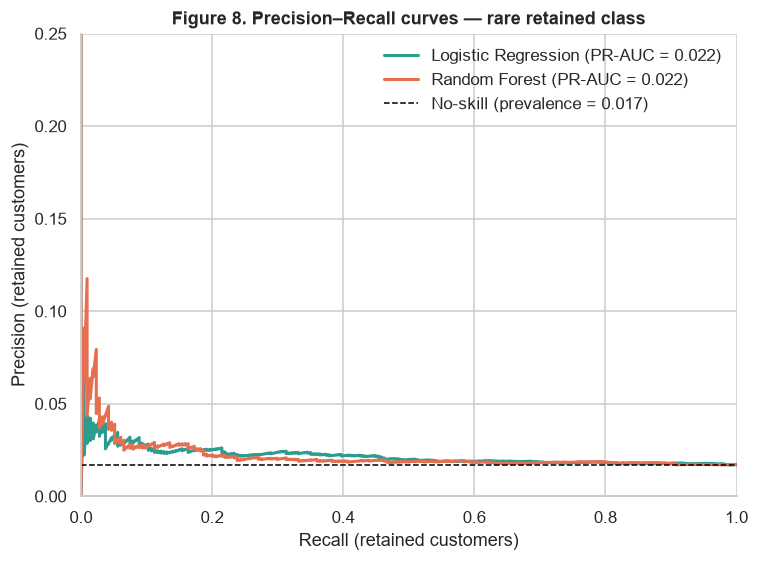

In [14]:
y_rare = (y_test == 0).astype(int)
fig, ax = plt.subplots(figsize=(7.0, 5.2))
for name, color in [('Logistic Regression', '#2a9d8f'), ('Random Forest', '#e76f51')]:
    precision, recall, _ = precision_recall_curve(y_rare, 1 - probabilities[name])
    score = average_precision_score(y_rare, 1 - probabilities[name])
    ax.plot(recall, precision, lw=2.0, color=color,
            label=f'{name} (PR-AUC = {score:.3f})')
ax.axhline(baseline, color='black', linestyle='--', lw=1,
           label=f'No-skill (prevalence = {baseline:.3f})')
ax.set_xlim(0, 1); ax.set_ylim(0, 0.25)
ax.set_xlabel('Recall (retained customers)')
ax.set_ylabel('Precision (retained customers)')
ax.set_title('Figure 8. Precision–Recall curves — rare retained class')
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig08_precision_recall.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 8 — Precision–Recall comparison

**01 — Effective visual design** The y-limit is fixed at 0.25 so the low-precision region remains legible while the no-skill prevalence line at 0.017 stays visible; the horizontal reference makes the scale interpretable in the same way a zero baseline does for bars.

**02 — Truthfulness** The no-skill line is drawn at the actual test-set prevalence of the **rare retained class** (0.017), which is the only fair PR benchmark here because the churn class is the majority. Both axes are labelled with the evaluated class, and the fixed y-limit is disclosed by the tick marks; no curve values fall outside the plotted range.

**03 — Functionality** The figure answers the operationally relevant question — at a given recall, how many customers flagged as likely to stay genuinely do so — which ROC curves obscure when 98.3% of cases belong to the other class.

**04 — Beauty** The palette is consistent with Figure 7, and the modest amount of ink (two lines and one reference) makes the comparison immediately readable.

**05 — Insightfulness** Both curves hover just above the 0.017 baseline, giving PR-AUC values around 0.022. The visual therefore shows that the models offer only marginal lift over random ranking when trying to find the rare retained customers — a decision-relevant insight that the 98.3% accuracy figure completely conceals.

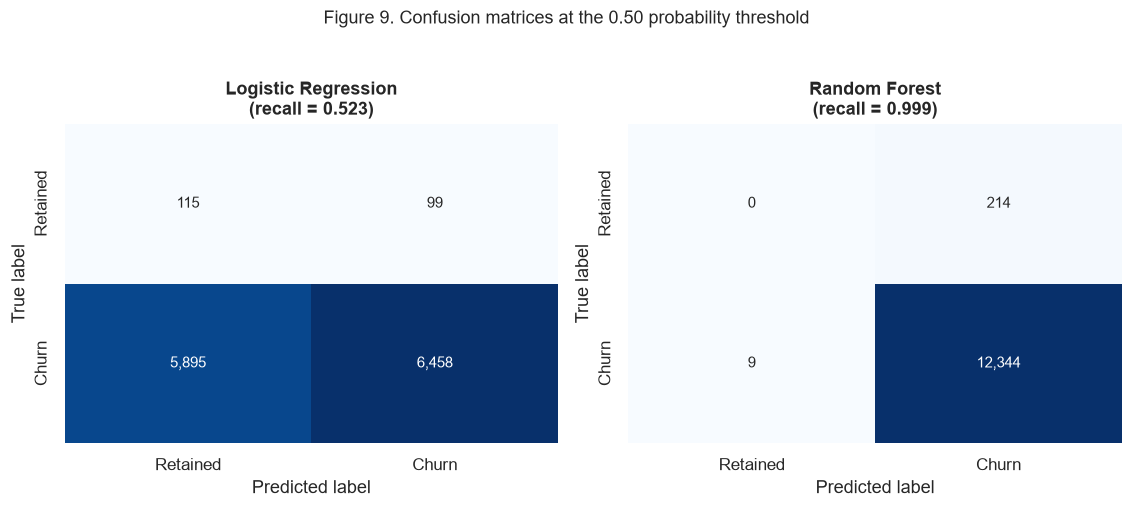

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4))
for ax, (name, color) in zip(axes, [('Logistic Regression', '#2a9d8f'),
                                     ('Random Forest', '#e76f51')]):
    pred = (probabilities[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=['Retained', 'Churn'],
                yticklabels=['Retained', 'Churn'], ax=ax)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(f'{name}\n(recall = {results.loc[name, "Recall (churn)"]:.3f})')
fig.suptitle('Figure 9. Confusion matrices at the 0.50 probability threshold', y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig09_confusion_matrices.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 9 — Confusion matrices

**01 — Effective visual design** Cell counts are printed directly, class labels are spelled out, and a single sequential colour map encodes magnitude without a distracting colour bar.

**02 — Truthfulness** The threshold (0.50) is stated in the suptitle and raw counts are printed in every cell, so the reader can verify that a large correct-churn count does not imply useful detection of the rare retained class. Identical axis orientation is used in both panels to avoid comparison errors.

**03 — Functionality** The side-by-side layout converts abstract metrics into four operational outcomes: correctly identified churners, missed churners, falsely flagged stayers and correctly identified stayers.

**04 — Beauty** Symmetrical panels, aligned titles and a light blue gradient keep the figure clean and consistent with the rest of the report.

**05 — Insightfulness** The matrices expose a stark failure mode: the class-weighted Logistic Regression misses roughly half of all churners (recall 0.523), while the Random Forest reaches 0.999 churn recall mainly by labelling almost everyone as churn — behaviour indistinguishable from the majority-class baseline. Neither pattern is a useful retention targeting rule.

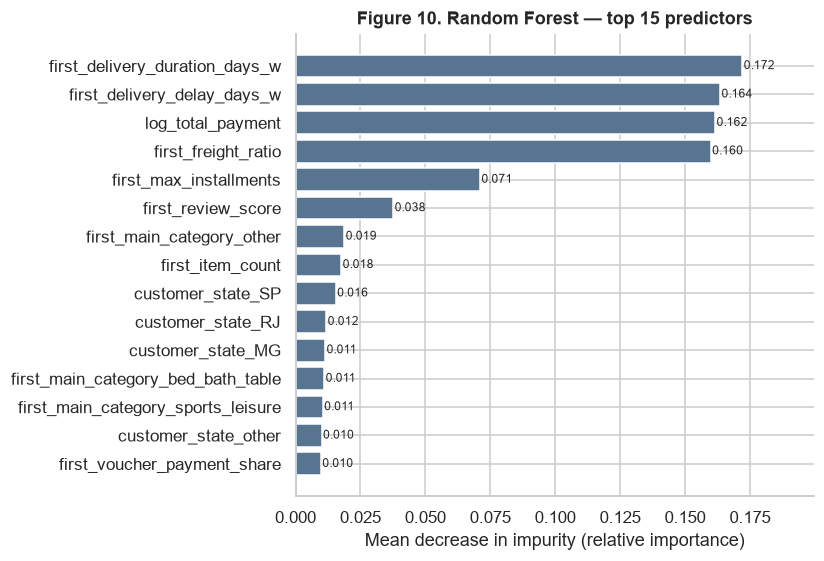

In [16]:
rf_pipe = models['Random Forest']
feature_names = rf_pipe.named_steps['prep'].get_feature_names_out()
clean_names = [n.split('__', 1)[-1] for n in feature_names]
importance = (pd.Series(rf_pipe.named_steps['clf'].feature_importances_,
                        index=clean_names)
              .sort_values(ascending=False).head(15)[::-1])

fig, ax = plt.subplots(figsize=(7.6, 5.2))
ax.barh(importance.index, importance.values, color='#577590')
ax.set_xlabel('Mean decrease in impurity (relative importance)')
ax.set_title('Figure 10. Random Forest — top 15 predictors')
for i, value in enumerate(importance.values):
    ax.text(value + 0.0005, i, f'{value:.3f}', va='center', fontsize=8)
ax.set_xlim(0, importance.max() * 1.16)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig10_feature_importance.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 10 — Feature importance

**01 — Effective visual design** A horizontal bar chart with sorted categories, a zero-based axis and direct numeric labels avoids the crowding that a vertical layout would create for long one-hot feature names.

**02 — Truthfulness** The metric is named exactly as "mean decrease in impurity", so the reader knows this is a model-internal split criterion and not a causal effect size. The top 15 are selected by value and the notebook code is available for inspection; the axis starts at zero, so bar lengths are proportional to the stated numbers.

**03 — Functionality** The figure ranks candidate drivers and guides which variables merit further investigation, while the wording of the caption guards against interpreting the ranking as causality.

**04 — Beauty** A single slate-blue hue and uncluttered horizontal spacing produce an easily scanned ranking with no redundant decoration.

**05 — Insightfulness** When the strongest importances remain small and clustered, the chart reveals that no single feature dominates — consistent with the weak univariate effects in Figures 2–6 and with the modest PR-AUC in Figure 8.

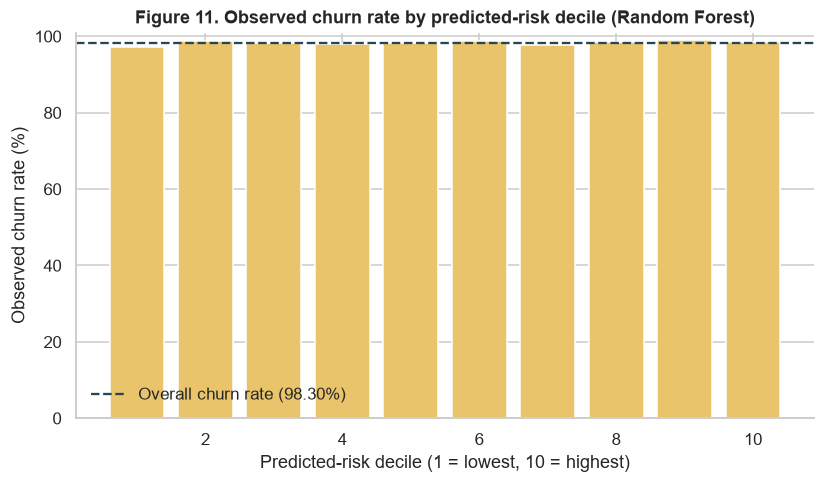

In [17]:
risk = pd.DataFrame({'y': y_test.to_numpy(), 'p': probabilities['Random Forest']})
risk['decile'] = pd.qcut(risk['p'], 10, labels=False, duplicates='drop')
lift = risk.groupby('decile')['y'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.bar(lift.index + 1, lift['mean'] * 100, color='#e9c46a')
ax.axhline(y_test.mean() * 100, color='#264653', linestyle='--', lw=1.5,
           label=f'Overall churn rate ({y_test.mean()*100:.2f}%)')
ax.set_xlabel('Predicted-risk decile (1 = lowest, 10 = highest)')
ax.set_ylabel('Observed churn rate (%)')
ax.set_title('Figure 11. Observed churn rate by predicted-risk decile (Random Forest)')
ax.set_ylim(0, 101)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig11_risk_deciles.png', bbox_inches='tight')
plt.show()

### Cairo visual-integrity self-assessment — Figure 11 — Risk decile validation

**01 — Effective visual design** Deciles are ordered from lowest to highest predicted risk, the y-axis starts at zero and a labelled overall-rate reference line is drawn, giving the reader a complete frame for judging lift.

**02 — Truthfulness** The reference line is computed from the held-out test set, not from the training data, and the deciles are formed from out-of-sample predictions only. The full 0–100% axis prevents the small differences between deciles from being visually exaggerated; the group sizes are retained in the notebook for audit.

**03 — Functionality** The figure translates model output into an operational question: if a team targets the highest-risk decile, how much richer is that pool than a random sample?

**04 — Beauty** A warm yellow against a dark reference line provides strong contrast with minimal ink; the single-series design avoids the confusion of overlapping model curves.

**05 — Insightfulness** The bars fluctuate between roughly 97% and 99% with no monotonic increase from the lowest to the highest predicted-risk decile. The chart therefore shows that the model provides no usable risk ranking — a clear example of a visual yielding insight by revealing the absence of an effect.

## 6. Conclusions and limitations

1. **The base rate dominates the label.** 98.30% of the cohort did not repeat within 180 days, so churn is the *majority* class and retention is the rare class (1.70%). Raw accuracy, churn-class recall and churn-class PR-AUC are base-rate artefacts and were deliberately subordinated to ROC-AUC, balanced accuracy and rare-class PR-AUC.
2. **Univariate signals are weak.** Delivery duration, review score, voucher usage, payment value and geography each shift churn by well under two percentage points (Figures 2–6). All rate plots use zero baselines so these small effects are not overstated.
3. **Neither classifier shows useful discrimination.** ROC-AUC is 0.556 (Logistic Regression) and 0.541 (Random Forest), both close to chance 0.5. Rare-class PR-AUC is about 0.022 against a 0.017 no-skill baseline — only a marginal lift (Figures 7–8). The confusion matrices (Figure 9) show that the Random Forest's 0.999 churn recall is achieved by predicting churn for almost everyone, not by finding genuine churners.
4. **Feature importance is diffuse** (Figure 10) and **risk-decile churn rates show no monotonic lift** (Figure 11). A retention campaign built on these first-order features alone would therefore be inefficient; richer behavioural, tenure and post-purchase experience data would be required.
5. **Interpretive limits.** Churn is inferred from purchase inactivity rather than stated intent; results describe one marketplace and one observation window; and all causal language is avoided because the design is observational. Reporting a "strong churn model" from these data would itself be a misleading visualisation narrative.

**Reproducibility.** Seed 42, stratified split, deterministic imputation and pipeline-fitted preprocessing make every reported number and figure regenerable by running all cells from a clean kernel.